In [24]:
import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from scipy.interpolate import interp1d
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight
import sys
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

plt.style.use('dark_background')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"{device}")

WINDOW_SIZE = 300
AXES = ['ax', 'ay', 'az', 'gx', 'gy', 'gz']

RAW_CSV = '../datasets/dataset.csv'
HN_BANK_CSV = '../datasets/dataset_HARD_NEGATIVES.csv'
NOISE_LOG_CSV = '../datasets/noise_dataset.csv'
BUTTONS_JSON = '../datasets/buttons.json'

BEST_MODEL_PTH = '../outputs/best_model.pth'
WEIGHTS_NPZ = '../outputs/weights.npz'
CLASS_NAMES = {0: "Background"}

if os.path.exists(BUTTONS_JSON):
    with open(BUTTONS_JSON, 'r', encoding='utf-8') as f:
        custom_classes = json.load(f)
        for k, v in custom_classes.items():
            class_id = int(k)
            if class_id != 0:
                CLASS_NAMES[class_id] = v.strip()
else:
    print(f"Файл {BUTTONS_JSON} не найден! Создайте его и укажите классы жестов.")
    sys.exit(1) 
print(f"Загружены классы из файла: {CLASS_NAMES}")

cuda
Загружены классы из файла: {0: 'Background', 1: 'Telegram', 2: 'Circle', 3: 'Circle_Rev', 4: 'YouTube'}


In [25]:
df_raw = pd.read_csv(RAW_CSV)

#ручное удаление после просмотра глазами
TRASH_IDS = [] 
df_clean = df_raw[~df_raw['gesture_id'].isin(TRASH_IDS)].copy()

# ебашим хард негативес
if os.path.exists(HN_BANK_CSV):
    df_hn = pd.read_csv(HN_BANK_CSV)
    if df_hn['gesture_id'].min() < 90000:
        df_hn['gesture_id'] = df_hn['gesture_id'] + 90000
    df_clean = pd.concat([df_clean, df_hn], ignore_index=True)
    print(f"Жестких негативов: {df_hn['gesture_id'].nunique()}")


lengths = df_clean.groupby('gesture_id').size()
bad_ids = lengths[lengths != WINDOW_SIZE].index.tolist()
if len(bad_ids) != 0:
    print(f"ОШИБКА! Найдены жесты с длиной != {WINDOW_SIZE}, ID: {bad_ids}")


for lbl, count in df_clean.groupby('label')['gesture_id'].nunique().items():
    print(f"Класс {lbl} ({CLASS_NAMES.get(lbl, 'Unknown')}): {count} примеров")
print(f"Всего {df_clean['gesture_id'].nunique()}")

Класс 0 (Background): 174 примеров
Класс 1 (Telegram): 118 примеров
Класс 2 (Circle): 115 примеров
Класс 3 (Circle_Rev): 110 примеров
Класс 4 (YouTube): 110 примеров
Всего 627


In [26]:
from gallery_builder import build_gallery

#Смотрим глазками
#build_gallery(df_clean, 'gallery.html')

In [27]:
X_raw_list, y_raw_list, gid_list = [], [], []

for gid, group in df_clean.groupby('gesture_id'):
    if len(group) == WINDOW_SIZE:
        sensor_mat = group[AXES].values.T.astype(np.float32)
        X_raw_list.append(sensor_mat)
        y_raw_list.append(int(group['label'].iloc[0]))
        gid_list.append(gid)

X_raw = np.array(X_raw_list) # (N, 6, 300)
y_raw = np.array(y_raw_list) # (N,)


splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(splitter.split(X_raw, y_raw))

X_train_pure, y_train_pure = X_raw[train_idx], y_raw[train_idx]
X_val_pure, y_val_pure = X_raw[val_idx], y_raw[val_idx]

print(f"Train: {X_train_pure.shape[0]} | Val : {X_val_pure.shape[0]}")

Train: 501 | Val : 126


In [28]:
def normalize_window(w):
    w = w.copy()
    w -= np.mean(w[:, :10], axis=1, keepdims=True)
    mean = np.mean(w, axis=1, keepdims=True)
    std = np.std(w, axis=1, keepdims=True)
    return (w - mean) / (std + 1e-6)

def get_edge_drift(w, edge='left', pad_size=30):
    """Генерирует фоновый дрейф, плавно вытекающий из края сигнала"""
    pad = np.zeros((6, pad_size))
    for ch in range(6):
        if edge == 'left':
            base_val = w[ch, 0]
            # Считаем шум по первым 20 точкам
            local_std = np.std(w[ch, :20]) + 1e-4
        else:
            base_val = w[ch, -1]
            # Считаем шум по последним 20 точкам
            local_std = np.std(w[ch, -20:]) + 1e-4
            
        # Генерируем низкочастотный фоновый дрейф 
        drift = gaussian_filter1d(np.random.normal(0, local_std * 1.5, pad_size), sigma=4)
        pad[ch] = base_val + drift
    return pad

def augment_sample(w):
    base = w.copy()
    out = [base] # 1. Оригинал
    # 2. Низкочастотный шум
    noise = np.zeros_like(base)
    for ch in range(6):
        channel_std = np.std(base[ch]) + 1e-4
        # sigma=15 дает плавные волны, имитирующие изменение наклона телефона
        noise[ch] = gaussian_filter1d(np.random.normal(0, channel_std * 0.8, 300), sigma=15)
    out.append(base + noise)
    
    # 3. Временной сдвиг
    shift = np.random.randint(20, 50)
    is_right_shift = np.random.rand() > 0.5
    shifted = np.zeros_like(base)
    
    if is_right_shift:
        shifted[:, shift:] = base[:, :-shift]
        shifted[:, :shift] = get_edge_drift(base, 'left', shift)
    else:
        shifted[:, :-shift] = base[:, shift:]
        shifted[:, -shift:] = get_edge_drift(base, 'right', shift)
    out.append(shifted)
    
    # 4. Искажение времени (Сжатие или Растяжение 50/50)
    warped = np.zeros_like(base)
    is_compress = np.random.rand() > 0.5
    
    if is_compress:
        # Сжимаем жест (имитация быстрого выполнения)
        pad_left = np.random.randint(20, 40)
        pad_right = np.random.randint(20, 40)
        target_len = 300 - pad_left - pad_right
        
        # Сплайновая интерполяция для плавного сжатия
        f = interp1d(np.arange(300), base, axis=1, kind='cubic')
        compressed = f(np.linspace(0, 299, target_len))
        
        left_pad = get_edge_drift(base, 'left', pad_left)
        right_pad = get_edge_drift(base, 'right', pad_right)
        
        warped = np.concatenate([left_pad, compressed, right_pad], axis=1)
        out.append(warped)
    else:
        # Растягиваем жест (имитация медленного выполнения)
        crop_left = np.random.randint(5, 20)
        crop_right = np.random.randint(5, 20)
        
        cropped = base[:, crop_left:300-crop_right]
        f = interp1d(np.arange(cropped.shape[1]), cropped, axis=1, kind='cubic')
        stretched = f(np.linspace(0, cropped.shape[1]-1, 300))
        
        out.append(stretched)
        
    return out

X_train_aug, y_train_aug = [], []
for sample, lbl in zip(X_train_pure, y_train_pure):
    for aug_w in augment_sample(sample):
        X_train_aug.append(normalize_window(aug_w))
        y_train_aug.append(lbl)

X_val_norm = np.array([normalize_window(w) for w in X_val_pure], dtype=np.float32)
y_val_norm = y_val_pure.astype(np.int64)

X_train_norm = np.array(X_train_aug, dtype=np.float32)
y_train_norm = np.array(y_train_aug, dtype=np.int64)

print(f"После аугментации Train: {X_train_norm.shape} | Val: {X_val_norm.shape}")

BATCH_SIZE = 32
train_loader = DataLoader(TensorDataset(torch.tensor(X_train_norm), torch.tensor(y_train_norm)), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(torch.tensor(X_val_norm), torch.tensor(y_val_norm)), batch_size=BATCH_SIZE, shuffle=False)

После аугментации Train: (2004, 6, 300) | Val: (126, 6, 300)


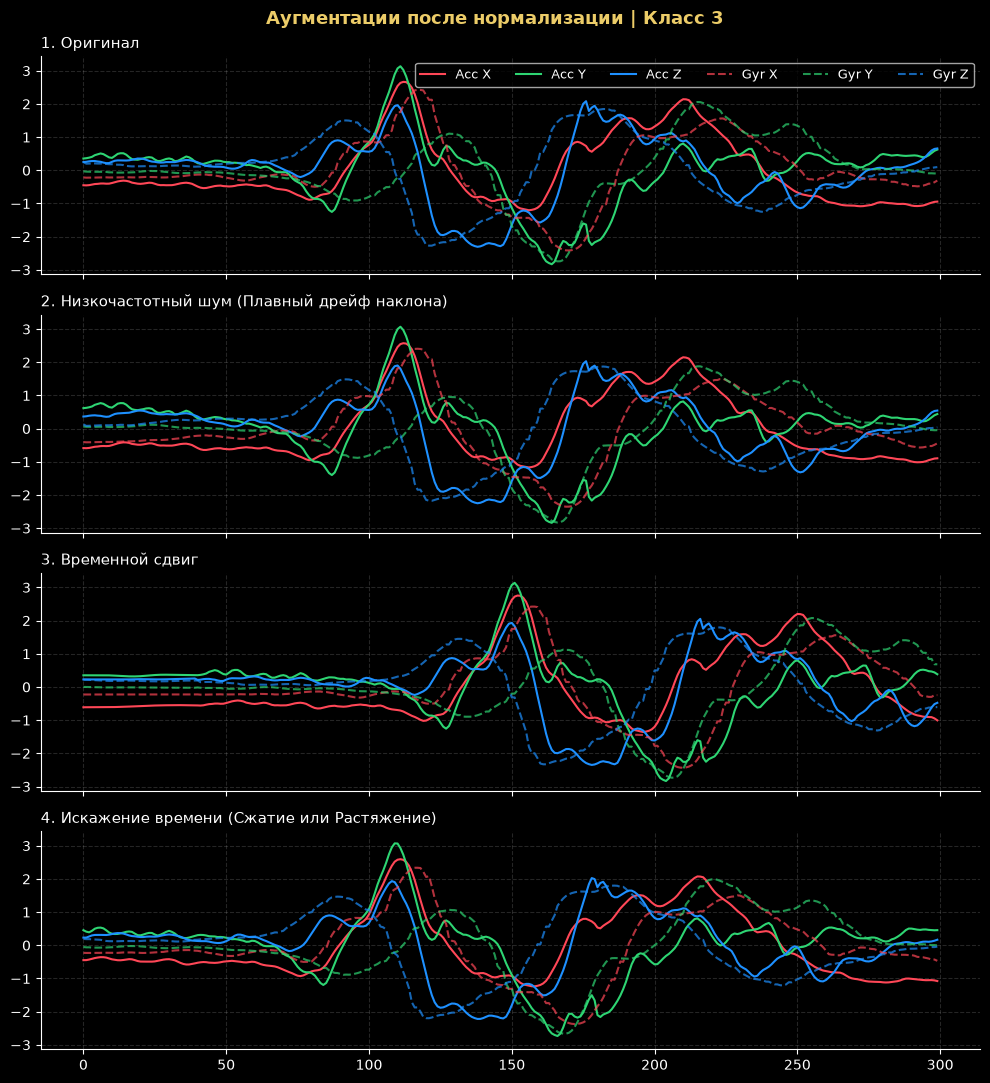

In [29]:
idx = np.random.randint(len(X_train_pure))
sample_w = X_train_pure[idx]
lbl = y_train_pure[idx]

aug_list = augment_sample(sample_w)
norm_aug_list = [normalize_window(w) for w in aug_list]

titles = [
    "1. Оригинал", 
    "2. Низкочастотный шум (Плавный дрейф наклона)", 
    "3. Временной сдвиг", 
    "4. Искажение времени (Сжатие или Растяжение)"
]

plt.style.use('dark_background')
fig, axes = plt.subplots(4, 1, figsize=(10, 11), sharex=True, sharey=True)
fig.suptitle(f"Аугментации после нормализации | Класс {lbl}", color='#eccc68', fontweight='bold', fontsize=13)

for i, (ax, w, title) in enumerate(zip(axes, norm_aug_list, titles)):
    # Акселерометр
    ax.plot(w[0], color='#ff4757', lw=1.5, label='Acc X' if i==0 else "")
    ax.plot(w[1], color='#2ed573', lw=1.5, label='Acc Y' if i==0 else "")
    ax.plot(w[2], color='#1e90ff', lw=1.5, label='Acc Z' if i==0 else "")
    
    # Гироскоп
    ax.plot(w[3], color='#ff4757', lw=1.5, ls='--', alpha=0.7, label='Gyr X' if i==0 else "")
    ax.plot(w[4], color='#2ed573', lw=1.5, ls='--', alpha=0.7, label='Gyr Y' if i==0 else "")
    ax.plot(w[5], color='#1e90ff', lw=1.5, ls='--', alpha=0.7, label='Gyr Z' if i==0 else "")
    
    ax.set_title(title, color='white', fontsize=11, loc='left')
    ax.grid(alpha=0.15, linestyle='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[0].legend(loc='upper right', ncol=6, fontsize=9)
plt.tight_layout()
plt.show()

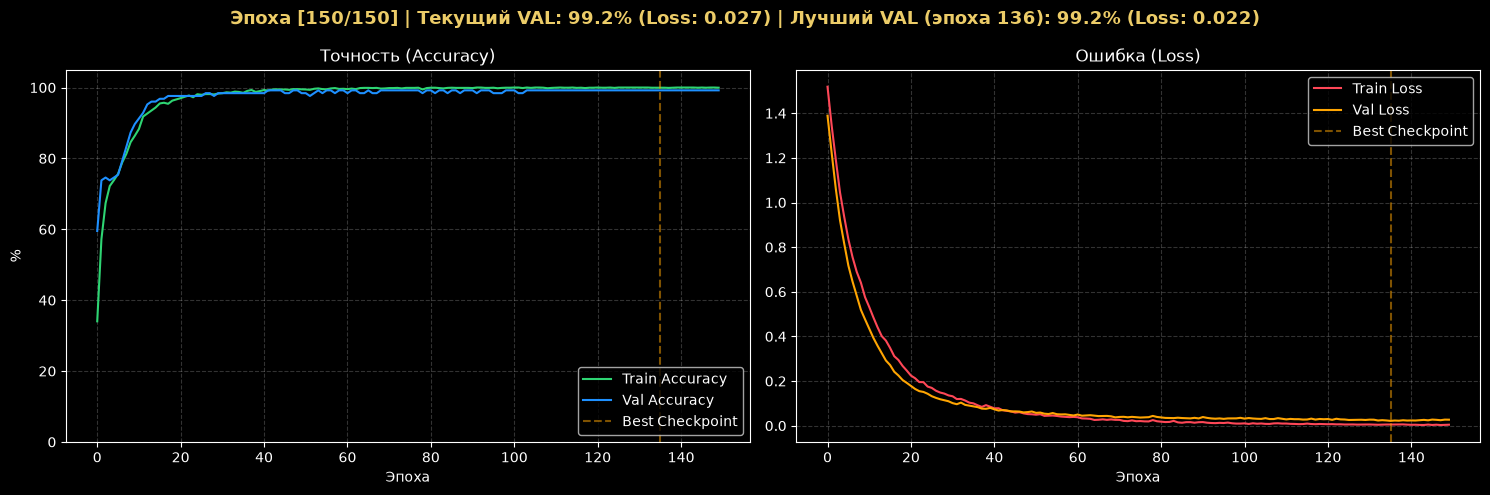

Лучший чекпоинт на эпохе 136: Val Acc = 99.21%, Val Loss = 0.0215


In [30]:
from IPython.display import clear_output

class EdgeCNN_v6(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            # Блок 1: (6, 300) -> (12, 100) -> Pool -> (12, 50)
            nn.Conv1d(in_channels=6, out_channels=12, kernel_size=7, stride=3, padding=1),
            nn.BatchNorm1d(12),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2, padding=0),
            
            # Блок 2: (12, 50) -> (24, 25) -> Pool -> (24, 12)
            nn.Conv1d(in_channels=12, out_channels=24, kernel_size=5, stride=2, padding=2),
            nn.BatchNorm1d(24),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2, padding=0),
            
            # Блок 3: (24, 12) -> (32, 6)
            nn.Conv1d(in_channels=24, out_channels=32, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            
            # Блок 4: (32, 6) -> (32, 6)
            nn.Conv1d(in_channels=32, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(32),
            nn.ReLU()
        )
        
        self.pool = nn.AdaptiveAvgPool1d(2) 
        self.dropout = nn.Dropout(0.25)
        
        
        self.classifier = nn.Linear(64, num_classes)
        
    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        return self.classifier(x)

NUM_CLASSES = len(np.unique(y_raw))
model = EdgeCNN_v6(num_classes=NUM_CLASSES).to(device)

class_weights = compute_class_weight('balanced', classes=np.unique(y_train_norm), y=y_train_norm)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=weights_tensor)
optimizer = optim.AdamW(model.parameters(), lr=0.0001, weight_decay=0.05)

EPOCHS = 150
PLOT_EVERY = 5  
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss = float('inf')
best_val_acc = 0.0
best_epoch = 0

for epoch in range(EPOCHS):
    model.train()
    r_loss, corr, tot = 0.0, 0, 0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        out = model(bx)
        loss = criterion(out, by)
        loss.backward()
        optimizer.step()
        
        r_loss += loss.item()
        corr += (out.argmax(1) == by).sum().item()
        tot += by.size(0)
        
    t_loss = r_loss / len(train_loader)
    t_acc = 100 * corr / tot
    
    model.eval()
    v_loss_sum, v_corr, v_tot = 0.0, 0, 0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            out = model(bx)
            v_loss_sum += criterion(out, by).item()
            v_corr += (out.argmax(1) == by).sum().item()
            v_tot += by.size(0)
            
    v_loss = v_loss_sum / len(val_loader)
    v_acc = 100 * v_corr / v_tot
    
    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['train_acc'].append(t_acc)
    history['val_acc'].append(v_acc)
    
    # Сохраняем лучшую модель строго по минимальному Val Loss
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        best_val_acc = v_acc
        best_epoch = epoch + 1
        torch.save(model.state_dict(), BEST_MODEL_PTH)

    # Живая отрисовка в процессе обучения
    if (epoch + 1) % PLOT_EVERY == 0 or epoch == 0 or (epoch + 1) == EPOCHS:
        clear_output(wait=True)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
        fig.suptitle(
            f"Эпоха [{epoch+1}/{EPOCHS}] | Текущий VAL: {v_acc:.1f}% (Loss: {v_loss:.3f}) | "
            f"Лучший VAL (эпоха {best_epoch}): {best_val_acc:.1f}% (Loss: {best_val_loss:.3f})",
            fontsize=13, fontweight='bold', color='#eccc68'
        )
        
        ax1.plot(history['train_acc'], label='Train Accuracy', color='#2ed573')
        ax1.plot(history['val_acc'], label='Val Accuracy', color='#1e90ff')
        ax1.axvline(best_epoch - 1, color='#ffa502', linestyle='--', alpha=0.5, label='Best Checkpoint')
        ax1.set_title('Точность (Accuracy)'); ax1.set_xlabel('Эпоха'); ax1.set_ylabel('%')
        ax1.set_ylim(0, 105); ax1.legend(loc='lower right'); ax1.grid(alpha=0.2, linestyle='--')

        ax2.plot(history['train_loss'], label='Train Loss', color='#ff4757')
        ax2.plot(history['val_loss'], label='Val Loss', color='#ffa502')
        ax2.axvline(best_epoch - 1, color='#ffa502', linestyle='--', alpha=0.5, label='Best Checkpoint')
        ax2.set_title('Ошибка (Loss)'); ax2.set_xlabel('Эпоха')
        ax2.legend(loc='upper right'); ax2.grid(alpha=0.2, linestyle='--')
        
        plt.tight_layout()
        plt.show()

print(f"Лучший чекпоинт на эпохе {best_epoch}: Val Acc = {best_val_acc:.2f}%, Val Loss = {best_val_loss:.4f}")

In [31]:
total_params = 0
    
for name, parameter in model.named_parameters():
    if not parameter.requires_grad:
        continue
    params = parameter.numel()
    total_params += params
    print(f"{name:<30} | {params:<10}")
        
print("-" * 45)
print(f"Всего параметров: {total_params}")
print(f"Размер в памяти:  {total_params * 4 / 1024:.2f} KB (float32)")

features.0.weight              | 504       
features.0.bias                | 12        
features.1.weight              | 12        
features.1.bias                | 12        
features.4.weight              | 1440      
features.4.bias                | 24        
features.5.weight              | 24        
features.5.bias                | 24        
features.8.weight              | 2304      
features.8.bias                | 32        
features.9.weight              | 32        
features.9.bias                | 32        
features.11.weight             | 3072      
features.11.bias               | 32        
features.12.weight             | 32        
features.12.bias               | 32        
classifier.weight              | 320       
classifier.bias                | 5         
---------------------------------------------
Всего параметров: 7945
Размер в памяти:  31.04 KB (float32)


               precision    recall  f1-score   support

0: Background      1.000     0.971     0.986        35
  1: Telegram      0.960     1.000     0.980        24
    2: Circle      1.000     1.000     1.000        23
3: Circle_Rev      1.000     1.000     1.000        22
   4: YouTube      1.000     1.000     1.000        22

     accuracy                          0.992       126
    macro avg      0.992     0.994     0.993       126
 weighted avg      0.992     0.992     0.992       126



C:\Users\Zver\AppData\Local\Temp\ipykernel_4116\579728320.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(BEST_MODEL_PTH, map_location=d

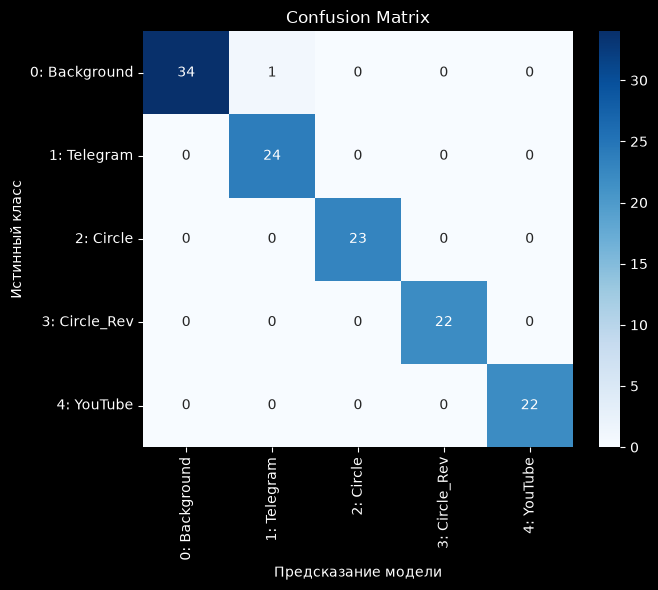

Веса веса экспортированы в '../outputs/weights.npz' (36.08 KB)


In [32]:
# Загружаем лучшую эпоху
model.load_state_dict(torch.load(BEST_MODEL_PTH, map_location=device))
model.eval()

all_preds, all_targets = [], []
with torch.no_grad():
    for bx, by in val_loader:
        bx = bx.to(device)
        preds = model(bx).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(by.numpy())

target_names = [f"{i}: {CLASS_NAMES.get(i, f'C{i}')}" for i in range(NUM_CLASSES)]
print(classification_report(all_targets, all_preds, target_names=target_names, digits=3))

cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix')
plt.ylabel('Истинный класс'); plt.xlabel('Предсказание модели')
plt.tight_layout()
plt.show()

#экспорт весов в numpy массив
numpy_weights = {k: v.cpu().numpy() for k, v in model.state_dict().items()}
np.savez_compressed(WEIGHTS_NPZ, **numpy_weights)
print(f"Веса веса экспортированы в '{WEIGHTS_NPZ}' ({os.path.getsize(WEIGHTS_NPZ) / 1024:.2f} KB)")

In [33]:
def export_numpy_math(model, filepath='model_math.py'):
    lines = [
        "import numpy as np",
        "",
        "def relu(x): return np.maximum(0, x)",
        "def softmax(x): ",
        "    e_x = np.exp(x - np.max(x))",
        "    return e_x / e_x.sum(axis=0)",
        "",
        "def conv1d(x, w_c, b_c, stride, pad):",
        "    out_c, _, k = w_c.shape",
        "    x_pad = np.pad(x, ((0,0), (pad, pad)), mode='constant')",
        "    out_len = (x.shape[1] + 2*pad - k) // stride + 1",
        "    out = np.zeros((out_c, out_len), dtype=np.float32)",
        "    for i in range(out_len):",
        "        out[:, i] = np.sum(w_c * x_pad[:, i*stride:i*stride+k], axis=(1,2)) + b_c",
        "    return out",
        "",
        "def batchnorm1d(x, w_bn, b_bn, mean, var, eps=1e-5):",
        "    std = np.sqrt(var + eps)",
        "    return ((x - mean[:, None]) / std[:, None]) * w_bn[:, None] + b_bn[:, None]",
        "",
        "def maxpool1d(x, k, stride, pad=0):",
        "    if pad > 0: x = np.pad(x, ((0,0), (pad, pad)), constant_values=-np.inf)",
        "    out_len = (x.shape[1] - k) // stride + 1",
        "    out = np.zeros((x.shape[0], out_len), dtype=np.float32)",
        "    for i in range(out_len): out[:, i] = np.max(x[:, i*stride:i*stride+k], axis=1)",
        "    return out",
        "",
        "def predict(window, w):",
        "    data = np.array(window, dtype=np.float32).T",
        "    data -= np.mean(data[:, :10], axis=1, keepdims=True)",
        "    x = (data - np.mean(data, axis=1, keepdims=True)) / (np.std(data, axis=1, keepdims=True) + 1e-6)",
    ]

    # Динамический парсинг графа PyTorch-модели
    for idx, layer in enumerate(model.features):
        if isinstance(layer, nn.Conv1d):
            s, p = layer.stride[0], layer.padding[0]
            lines.append(f"    # Слой {idx}: Conv1d")
            lines.append(f"    x = conv1d(x, w['features.{idx}.weight'], w['features.{idx}.bias'], stride={s}, pad={p})")
        elif isinstance(layer, nn.BatchNorm1d):
            lines.append(f"    x = batchnorm1d(x, w['features.{idx}.weight'], w['features.{idx}.bias'], w['features.{idx}.running_mean'], w['features.{idx}.running_var'])")
        elif isinstance(layer, nn.ReLU):
            lines.append(f"    x = relu(x)")
        elif isinstance(layer, nn.MaxPool1d):
            k, s, p = layer.kernel_size, layer.stride, layer.padding
            lines.append(f"    x = maxpool1d(x, k={k}, stride={s}, pad={p})")

    lines.extend([
        "",
        "    # AdaptiveAvgPool1d(2) + Classifier",
        "    x = np.mean(x.reshape(x.shape[0], 2, -1), axis=2).flatten()",
        "    logits = np.dot(w['classifier.weight'], x) + w['classifier.bias']",
        "    probs = softmax(logits)",
        "    return np.argmax(probs), np.max(probs)",
        ""
    ])

    with open(filepath, 'w', encoding='utf-8') as f:
        f.write('\n'.join(lines))
    print(f"Математика сети скомпилирована в {filepath}")

#export_numpy_math(model, '../outputs/model_math.py')

In [ ]:
#До внедрения Active Learning (сохранения ошибок прямо на телефоне по кнопке громкости), я использовал этот подход. 
#Я записывал длинные логи фоновой активности (ходьба, метро, набор текста), резал их на окна, фильтровал по дисперсии амплитуды (чтобы отсечь состояние покоя) и прогонял через модель. Если модель уверенно (conf > 0.85) путала фон с каким-то жестом, этот кусок сохранялся в dataset_HARD_NEGATIVES.csv с label=0. 
#Сейчас эта функция отключена, так как infer.py пополняет этот банк автоматически в реальном време

def mine_hard_negatives(noise_csv_path, bank_csv_path, var_threshold=0.5, conf_threshold=0.85):
    if not os.path.exists(noise_csv_path):
        print(f"[-] Файл {noise_csv_path} не найден.")
        return
        
    model.load_state_dict(torch.load(BEST_MODEL_PTH, map_location=device,weights_only=True))
    model.eval()
    
    df_noise = pd.read_csv(noise_csv_path)
    sensor_data = df_noise[AXES].values.astype(np.float32)
    
    STRIDE = 300 
    norm_windows, raw_windows, meta_info = [], [], []
    
    for i in range(0, len(sensor_data) - WINDOW_SIZE, STRIDE):
        raw_w = sensor_data[i : i + WINDOW_SIZE] # (300, 6)
        acc_var = np.var(raw_w[:, :3], axis=0).sum()
        
        if acc_var >= var_threshold:
            norm_w = normalize_window(raw_w.T) # (6, 300)
            norm_windows.append(norm_w)
            raw_windows.append(raw_w)          
            meta_info.append((i, acc_var))
            
    if not norm_windows:
        print("Ни одно окно не прошло порог дисперсии.")
        return
        
    tensor_x = torch.tensor(np.array(norm_windows), dtype=torch.float32).to(device)
    with torch.no_grad():
        probs = torch.softmax(model(tensor_x), dim=1)
        confs, preds = torch.max(probs, dim=1)
        
    confs, preds = confs.cpu().numpy(), preds.cpu().numpy()
    
    next_hn_id = 90000
    existing_df = pd.DataFrame()
    if os.path.exists(bank_csv_path):
        existing_df = pd.read_csv(bank_csv_path)
        if not existing_df.empty:
            next_hn_id = int(existing_df['gesture_id'].max()) + 1
            
    new_rows = []
    mined_count = 0
    for idx, (pred, conf) in enumerate(zip(preds, confs)):
        if pred != 0 and conf >= conf_threshold:
            orig_i, var_val = meta_info[idx]
            raw_w = raw_windows[idx] # (300, 6)
            print(f"{orig_i} | Предсказан : {pred} ({CLASS_NAMES.get(pred)}) | Conf: {conf:.3f} | Var: {var_val:.2f}")
            
            for row in raw_w: # Ровно 300 шагов сырого сигнала
                new_rows.append({
                    'ax': row[0], 'ay': row[1], 'az': row[2],
                    'gx': row[3], 'gy': row[4], 'gz': row[5],
                    'label': 0,
                    'gesture_id': next_hn_id
                })
            next_hn_id += 1
            mined_count += 1
            
    if new_rows:
        df_new_hn = pd.DataFrame(new_rows)
        df_combined_hn = pd.concat([existing_df, df_new_hn], ignore_index=True)
        df_combined_hn.to_csv(bank_csv_path, index=False)
        print(f"\nнегативов: {mined_count}. Всего '{bank_csv_path}': {df_combined_hn['gesture_id'].nunique()} окон.")
    else:
        print("\nМодель не допустила ни одной уверенной ошибки на этом логе шума!")


mine_hard_negatives(NOISE_LOG_CSV, HN_BANK_CSV, var_threshold=0.5, conf_threshold=0.85)